# Analysis of Relational Attention for XOR
The purpose of this notebook is to analyze the linear relational model trained on the XOR task.

## Imports

In [1]:
import numpy as np
import math
import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

from relational_attention.tasks import XORDataset
from relational_attention.models import RelationalAttentionHead, AttentionClassifier
from relational_attention.training import evaluate_model

In [2]:
torch.manual_seed(42)

## Load model

In [3]:
checkpoint = torch.load("../../data/linear_relational_attention_xor_full.pt", map_location="cpu")

In [4]:
# Recreate the same architecture
model = AttentionClassifier(
    embed_dim=checkpoint["metadata"]["embed_dim"],
    head_dim=checkpoint["metadata"]["head_dim"],
    attn_cls=RelationalAttentionHead,
    context_size=checkpoint["metadata"]["context_size"],
    linear=True
)
model.load_state_dict(checkpoint["model_state"])
model.eval()

AttentionClassifier(
  (attn): RelationalAttentionHead(
    (W_q): Linear(in_features=2, out_features=1, bias=False)
    (W_k): Linear(in_features=2, out_features=1, bias=False)
  )
  (fc): Linear(in_features=2, out_features=1, bias=True)
)

## Visualize query, key, value matrices

In [5]:
attn_head = model.attn
Q_weights = attn_head.W_q.weight.data
K_weights = attn_head.W_k.weight.data
V_matrix = attn_head.V.data

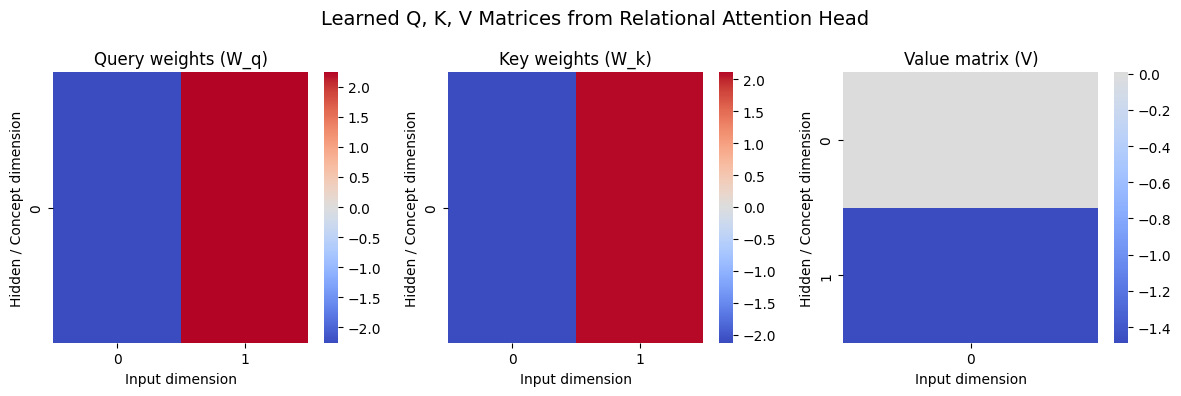

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.heatmap(Q_weights, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Query weights (W_q)")

sns.heatmap(K_weights, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Key weights (W_k)")

sns.heatmap(V_matrix, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Value matrix (V)")

for ax in axes:
    ax.set_xlabel("Input dimension")
    ax.set_ylabel("Hidden / Concept dimension")

plt.suptitle("Learned Q, K, V Matrices from Relational Attention Head", fontsize=14)
plt.tight_layout()
plt.show()

## Query-Key weight

In [7]:
sim_qk = (Q_weights.T @ K_weights) / (K_weights.size(-1) ** 0.5)
sim_qk.shape

torch.Size([2, 2])

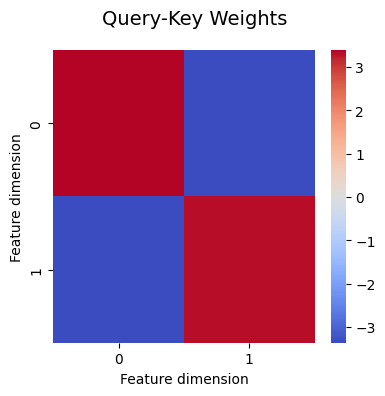

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
sns.heatmap(sim_qk, cmap="coolwarm", center=0, ax=ax)
ax.set_xlabel("Feature dimension")
ax.set_ylabel("Feature dimension")

plt.suptitle("Query-Key Weights", fontsize=14)
plt.tight_layout()
plt.show()